<a href="https://colab.research.google.com/github/garvitSharma24112/machine-learning/blob/main/single_linkage_and_complete_linkage_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Load and Explore the Dataset

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler

# Download and load the dataset from a public URL
filepath = 'https://raw.githubusercontent.com/SteffiPeTaffy/machineLearningAZ/master/Machine%20Learning%20A-Z%20Template%20Folder/Part%204%20-%20Clustering/Section%2025%20-%20Hierarchical%20Clustering/Mall_Customers.csv'
df = pd.read_csv(filepath)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (200, 5)


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


### 2. Preprocess Data
We will select standard features for clustering: **Annual Income (k$)** and **Spending Score (1-100)**, and scale them so both features contribute equally.

In [4]:
# Select features for clustering
X = df[['Annual Income (k$)', 'Spending Score (1-100)']].values

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


### 3. Hierarchical Clustering: Single Linkage

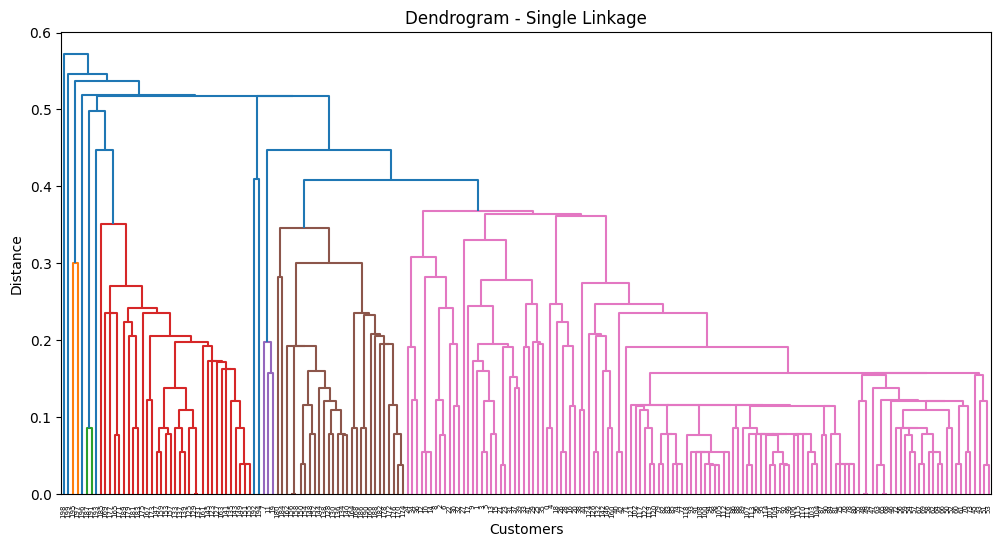

In [5]:
# Generate single linkage merge matrix
Z_single = linkage(X_scaled, method='single', metric='euclidean')

# Plot Dendrogram for Single Linkage
plt.figure(figsize=(12, 6))
plt.title("Dendrogram - Single Linkage")
dendrogram(Z_single)
plt.xlabel("Customers")
plt.ylabel("Distance")
plt.show()


### 4. Hierarchical Clustering: Complete Linkage

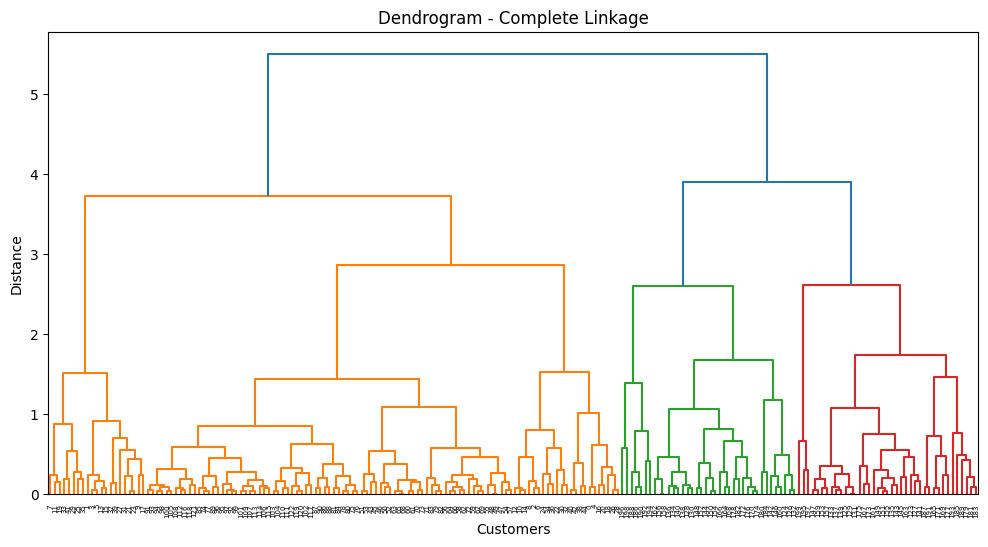

In [6]:
# Generate complete linkage merge matrix
Z_complete = linkage(X_scaled, method='complete', metric='euclidean')

# Plot Dendrogram for Complete Linkage
plt.figure(figsize=(12, 6))
plt.title("Dendrogram - Complete Linkage")
dendrogram(Z_complete)
plt.xlabel("Customers")
plt.ylabel("Distance")
plt.show()


### 5. Compare Cluster Visualization
Based on the complete linkage dendrogram, 5 clusters appear to be a distinct division. Let's compare the assignments made by both methods using 5 clusters.

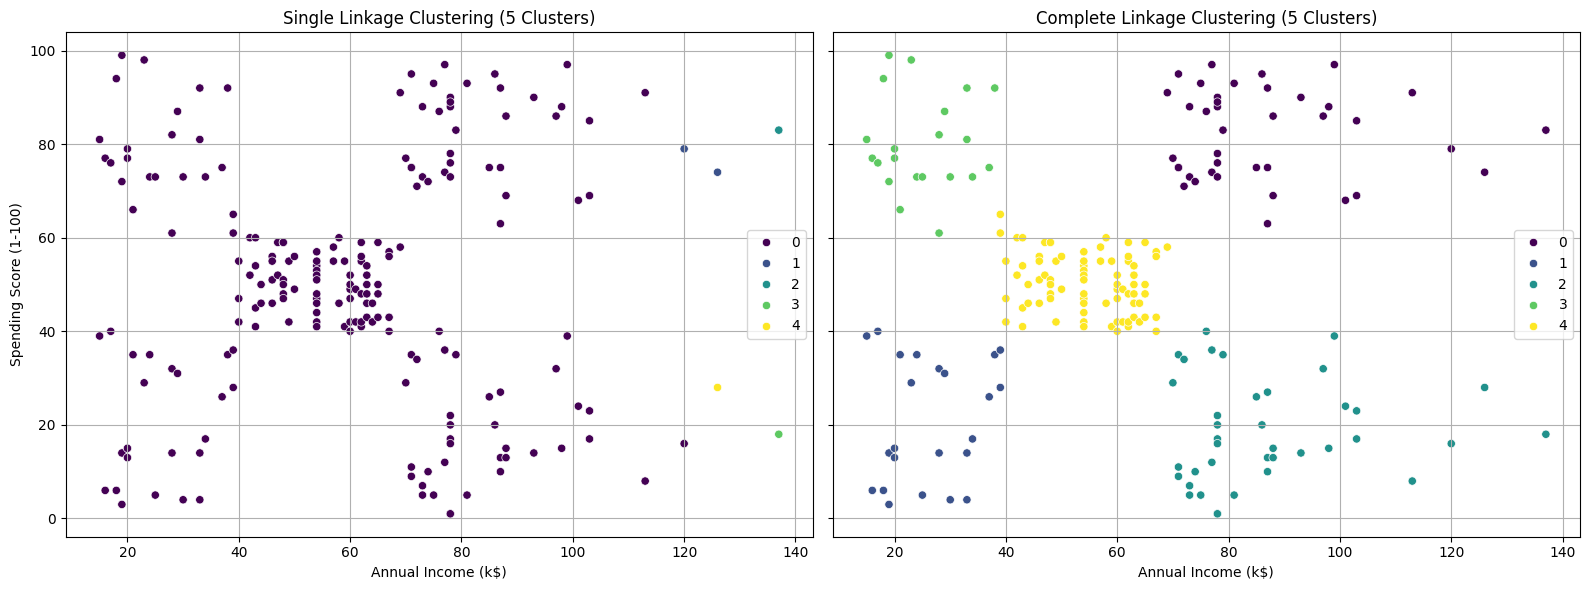

In [7]:
n_clusters = 5

# Apply Agglomerative Clustering with Single Linkage
cluster_single = AgglomerativeClustering(n_clusters=n_clusters, linkage='single')
labels_single = cluster_single.fit_predict(X_scaled)

# Apply Agglomerative Clustering with Complete Linkage
cluster_complete = AgglomerativeClustering(n_clusters=n_clusters, linkage='complete')
labels_complete = cluster_complete.fit_predict(X_scaled)

# Plot comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

sns.scatterplot(x=df['Annual Income (k$)'], y=df['Spending Score (1-100)'], hue=labels_single, palette='viridis', ax=axes[0])
axes[0].set_title('Single Linkage Clustering (5 Clusters)')
axes[0].grid(True)

sns.scatterplot(x=df['Annual Income (k$)'], y=df['Spending Score (1-100)'], hue=labels_complete, palette='viridis', ax=axes[1])
axes[1].set_title('Complete Linkage Clustering (5 Clusters)')
axes[1].grid(True)

plt.tight_layout()
plt.show()
